<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [1]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

Setup complete


---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [2]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


,count
label_text,
rec.sport.hockey,600
soc.religion.christian,599
rec.motorcycles,598
rec.sport.baseball,597
sci.crypt,595
sci.med,594
rec.autos,594
sci.space,593
comp.windows.x,593


In [3]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

Label: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [5]:
print(sorted(df["label_text"].unique()))

my_categories = ["rec.sport.baseball", "soc.religion.christian", "sci.space"]  # YOUR CODE HERE: 3 category names copied from the list above

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Selected categories: ['rec.sport.baseball', 'soc.religion.christian', 'sci.space']
Filtered dataset: 1789 documents


,count
label_text,
soc.religion.christian,599
rec.sport.baseball,597
sci.space,593


### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)



<!-- ANSWER lab3.1-A2 -->
**Your answer:**

I chose rec.sport.baseball, sci.space, and soc.religion.christian because they talk about completely different topics: sports, space science, and religion. They are very different from each other, which makes it much easier to see clear patterns. Because the subjects don't really overlap, I expect totally different vocabularies: words like runs, pitcher, and game for baseball; NASA, orbit, and launch for space; and words like God, faith, and church for religion.


<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [6]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

hello check this email me at price


### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [7]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    # 1. preprocess_basic
    text = preprocess_basic(text)

    # 2. tokenize
    tokens = text.split()

    # 3. remove stop words
    tokens = [w for w in tokens if w not in stop_words]

    # 4. lemmatize (por defecto lematiza como sustantivo con WordNet)
    tokens = [lemmatizer.lemmatize(w) for w in tokens]

    # 5. keep words with at least 3 characters
    tokens = [w for w in tokens if len(w) >= 3]

    # 6. join back into a string
    return " ".join(tokens)
    pass

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [9]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

article tom baker understanding expected error basically known bug warning system software thing checked right value yet set till launch suchlike rather fix code possibly introduce new bug tell crew see warning liftoff ignore


---
# Part C – Visualization

## C.1 Most frequent words per category

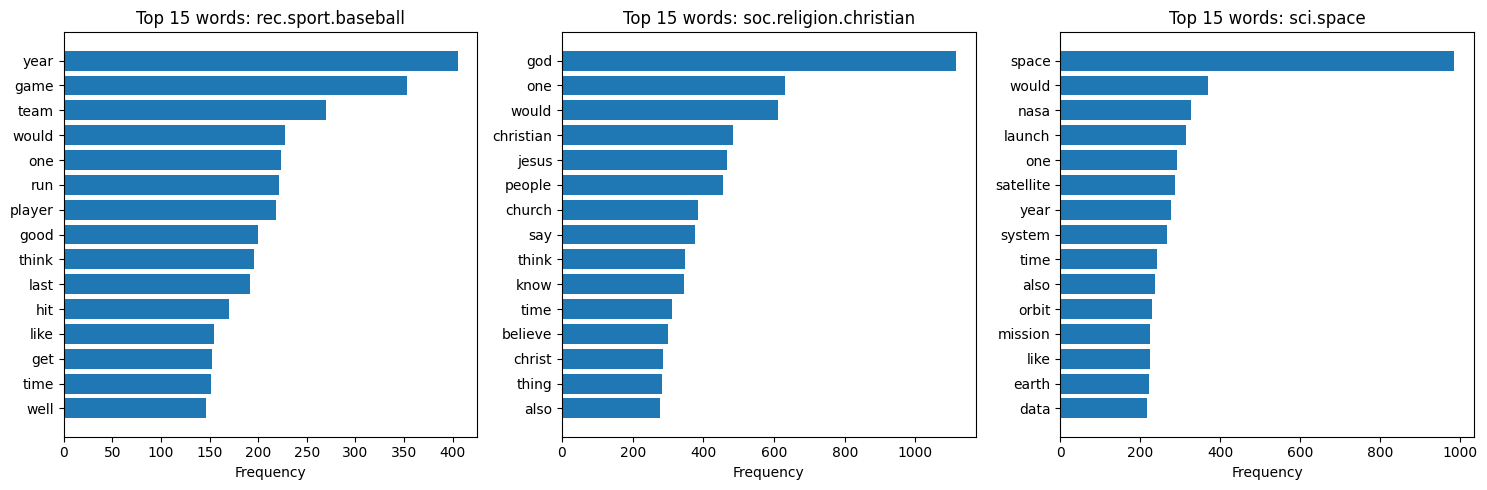

In [10]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**Your answer:**

1- rec.sport.baseball: game, team, run, player, hit.   
soc.religion.christian: god, christian, jesus, church, christ, believe.   
sci.space: space, nasa, launch, satellite, orbit, mission.   

2- Would, one and time. They are generic words used across all topics.

3- Yes. Despite the presence of generic words, the dominant terms in each list are distinctive as game, team, and player for baseball- god, christian, and jesus for religion- and space, nasa, and launch for space exploration.
<!-- END ANSWER -->

## C.2 Word clouds

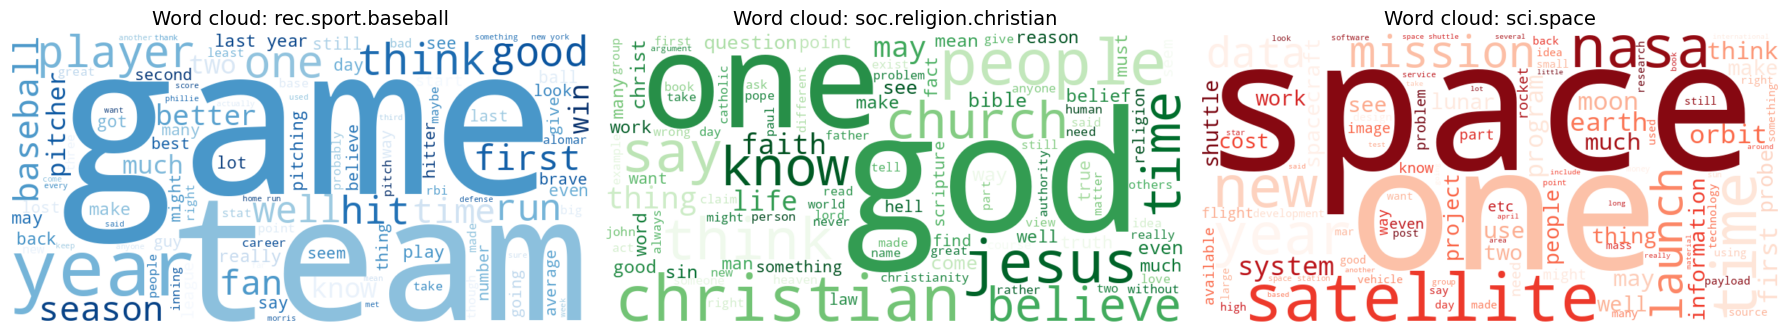

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

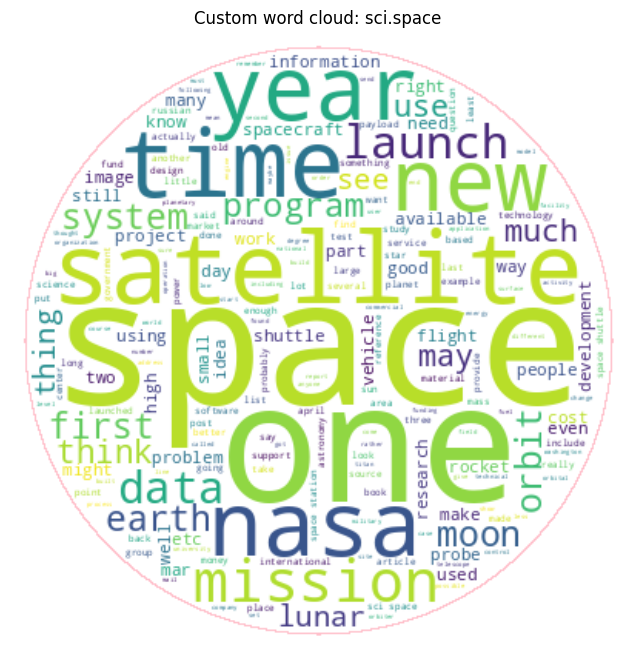

In [13]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = "sci.space"
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]
wordcloud_masked = WordCloud(
    background_color="white",
    mask=mask,
    contour_width=1,
    contour_color="pink"
).generate(" ".join(texts))

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [14]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary: ['deep' 'great' 'is' 'learning' 'love' 'machine' 'too']


,deep,great,is,learning,love,machine,too
0,0,0,0,1,1,1,0
1,0,1,1,1,0,1,0
2,1,0,0,1,1,0,1


### Exercise D.1 – Bag of Words of your corpus

In [16]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(max_features=1000, min_df=5, max_df=0.95)
bow_matrix_full = bow_vectorizer_full.fit_transform(df_filtered["text_clean"])

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1789, 1000)
Sparsity: 96.4% of zeros
First 20 words: ['ability' 'able' 'absolute' 'accept' 'access' 'according' 'account'
 'across' 'act' 'action' 'activity' 'actually' 'add' 'address' 'aerospace'
 'age' 'agency' 'ago' 'agree' 'ahead']


### Exercise D.2 – Document similarity

In [17]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
similarity_matrix = cosine_similarity(bow_matrix_full)

# 2. Find the most similar pair of distinct documents (ignore the diagonal)
sim_matrix_no_diag = similarity_matrix.copy()
np.fill_diagonal(sim_matrix_no_diag, -1)

i, j = np.unravel_index(np.argmax(sim_matrix_no_diag), sim_matrix_no_diag.shape)
most_similar_idx = (int(i), int(j))
most_similar_score = float(sim_matrix_no_diag[i, j])

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1789, 1789)
Most similar documents: (734, 765), score = 1.000

Document 1 (sci.space):
Can someone please remind me who said a well known quotation? 

He was sitting atop a rocket awaiting liftoff and afterwards, in answer to
the question what he had been thinking about, said (approximately) "half a
million components, each has to work perfectly, each supplied by the lowest
bidder....

Document 2 (sci.space):
Can someone please remind me who said a well known quotation? 

He was sitting atop a rocket awaiting liftoff and afterwards, in answer to
the question what he had been thinking about, said (approximately) "half a
million components, each has to work perfectly, each supplied by the lowest
bidder....


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**

1- Yes, both documents belong to the sci.space category.
2- They are the same

3- Yes, it is highly meaningful in this case. A similarity of 1.0 accurately detects exact duplicate or cross-posted text within the corpus, which is one of the primary use cases for Bag-of-Words similarity

<!-- END ANSWER -->

---
# Part E – TF-IDF

In [18]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

,deep,great,is,learning,love,machine,too
0,0.000,0.000,0.000,0.481,0.620,0.620,0.000
1,0.000,0.584,0.584,0.345,0.000,0.445,0.000
2,0.584,0.000,0.000,0.345,0.445,0.000,0.584


In [19]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

Scores of the word 'learning' (present in every document):
  BoW:    [1, 1, 1]
  TF-IDF: [0.481, 0.345, 0.345] -> lower weight for a word shared by all documents


### Exercise E.1 – TF-IDF of your corpus and top words per category

In [20]:
tfidf_vectorizer_full = TfidfVectorizer(max_features=1000, min_df=5, max_df=0.95)
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(df_filtered["text_clean"])
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    # 1. indices of the documents of this category
    indices = df_filtered.index[df_filtered["label_text"] == category].tolist()

    # 2. their TF-IDF rows
    category_tfidf = tfidf_matrix_full[indices]

    # 3. mean score of each word over these rows
    mean_scores = np.asarray(category_tfidf.mean(axis=0)).ravel()

    # 4. the n words with the highest mean
    feature_names = np.array(tfidf_vectorizer_full.get_feature_names_out())
    top_indices = np.argsort(mean_scores)[::-1][:n]

    return feature_names[top_indices].tolist()
    pass

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

TF-IDF matrix shape: (1789, 1000)

Top TF-IDF words for 'rec.sport.baseball':
['game', 'year', 'team', 'player', 'run', 'baseball', 'hit', 'last', 'think', 'fan']

Top TF-IDF words for 'soc.religion.christian':
['god', 'christian', 'jesus', 'would', 'one', 'church', 'people', 'bible', 'christ', 'say']

Top TF-IDF words for 'sci.space':
['space', 'would', 'like', 'nasa', 'one', 'launch', 'orbit', 'get', 'moon', 'could']


### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**Your answer:**

1- rec.sport.baseball: baseball and fan    
soc.religion.christian: bible  
sci.space: moon and could

2- rec.sport.baseball: would, one, good, get, time, well.   
soc.religion.christian: think, know, time, believe, thing, also.   sci.space: satellite, year, system, time, also, mission, earth, data.   

3- TF-IDF captures the topic significantly better.
Bag-of-Words only measure frequency, so uninformative conversational terms like would, one, like, and time dominate the top rankings simply because people use them constantly across every forum.
TF-IDF multiplies term frequency by IDF, which penalizes words that appear across many different documents in all categories while heavily boosting words that appear predominantly within a specific group. As a result, domain-defining terms like baseball, fan, bible, and moon are promoted, providing a much clearer thematic fingerprint.
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [21]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

Bigrams:  [('I', 'love'), ('love', 'natural'), ('natural', 'language'), ('language', 'processing'), ('processing', 'and'), ('and', 'machine'), ('machine', 'learning')]
Trigrams: [('I', 'love', 'natural'), ('love', 'natural', 'language'), ('natural', 'language', 'processing'), ('language', 'processing', 'and'), ('processing', 'and', 'machine'), ('and', 'machine', 'learning')]
Bigram features: ['is great' 'learning is' 'love machine' 'machine learning']


### Exercise F.1 – Most frequent bigrams per category

In [22]:
def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    # 1. CountVectorizer(ngram_range=(2, 2), min_df=3) fitted on the texts
    vec = CountVectorizer(ngram_range=(2, 2), min_df=3)
    X = vec.fit_transform(texts)

    # 2. sum the columns to count each bigram
    counts = np.asarray(X.sum(axis=0)).ravel()
    features = np.array(vec.get_feature_names_out())

    # 3. return the n most frequent (bigram, count)
    top_indices = np.argsort(counts)[::-1][:n]
    return [(features[i], int(counts[i])) for i in top_indices]
    pass

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'rec.sport.baseball':
  last year: 98
  new york: 49
  home run: 44
  red sox: 35
  major league: 25
  pitching staff: 22
  los angeles: 21
  world series: 21
  san francisco: 20
  san diego: 19
  blue jay: 17
  white sox: 17
  run scored: 17
  year old: 17
  hall fame: 16

Top bigrams for 'soc.religion.christian':
  holy spirit: 62
  jesus christ: 45
  would like: 36
  father son: 36
  catholic church: 28
  absolute truth: 27
  answer question: 26
  non christian: 25
  new testament: 25
  would say: 22
  second coming: 20
  many people: 20
  word god: 20
  eternal life: 19
  jesus say: 18

Top bigrams for 'sci.space':
  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  remote sensing: 32
  commercial space: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa gov: 24
  nasa ames: 24
  space technology: 23
  pub space: 21


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [23]:
class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}  # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        # YOUR CODE HERE
        for text in texts:
            tokens = text.split()
            self.unigram_counts.update(tokens)
            for w1, w2 in zip(tokens[:-1], tokens[1:]):
                if w1 not in self.bigram_counts:
                    self.bigram_counts[w1] = Counter()
                self.bigram_counts[w1][w2] += 1

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        # YOUR CODE HERE
        if word not in self.bigram_counts or self.unigram_counts[word] == 0:
            return []

        total_w1 = self.unigram_counts[word]
        next_words = self.bigram_counts[word].most_common(top_n)
        return [(next_w, count / total_w1) for next_w, count in next_words]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


In [24]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["Sky", "Ball", "Church", "Priest", "Grey"]  # YOUR CODE HERE

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")


'Sky' ->
  survey: 0.052
  telescope: 0.034
  theory: 0.034
  zone: 0.034
  one: 0.034

'Ball' ->
  live: 0.140
  hit: 0.056
  caught: 0.037
  park: 0.028
  going: 0.028

'Church' ->
  one: 0.016
  today: 0.013
  believe: 0.010
  would: 0.010
  much: 0.008

'Priest' ->
  parish: 0.044
  present: 0.044
  apparently: 0.022
  pastor: 0.022
  minister: 0.022

'Grey' ->
  haired: 0.333
  hair: 0.333
  word: 0.333


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**

1- Sensible predictions:'Grey' -> 'haired' : (grey-haired / grey hair).   
'Ball' -> 'park' (or 'hit'):Produces a direct domain from baseball (ballpark / ball hit).   
Poor predictions:'Church' -> 'would' (or 'one'): A generic modal/filler word that carries no semantic link to religion, appearing purely due to high baseline frequency.   
'Sky' -> 'one': An uninformative pairing that does not reflect natural language usage.

2- Zero long-term memory, high data sparsity and frequency bias that tend to predict ubiquitous general words (one, would) after almost any query word rather than meaningful topical terminology.   

3- Higher-order n-grams: Transition to trigrams or 4-grams to incorporate a larger history context , producing much more cohesive phrasing.
Smoothing and backoff techniques: Apply algorithms to avoid zero-probability penalties for unseen bigrams and intelligently fall back to lower-order n-grams.
Neural language models: Replace count tables with dense vector representations that capture semantic similarity and evaluate whole-sentence context.
<!-- END ANSWER -->

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

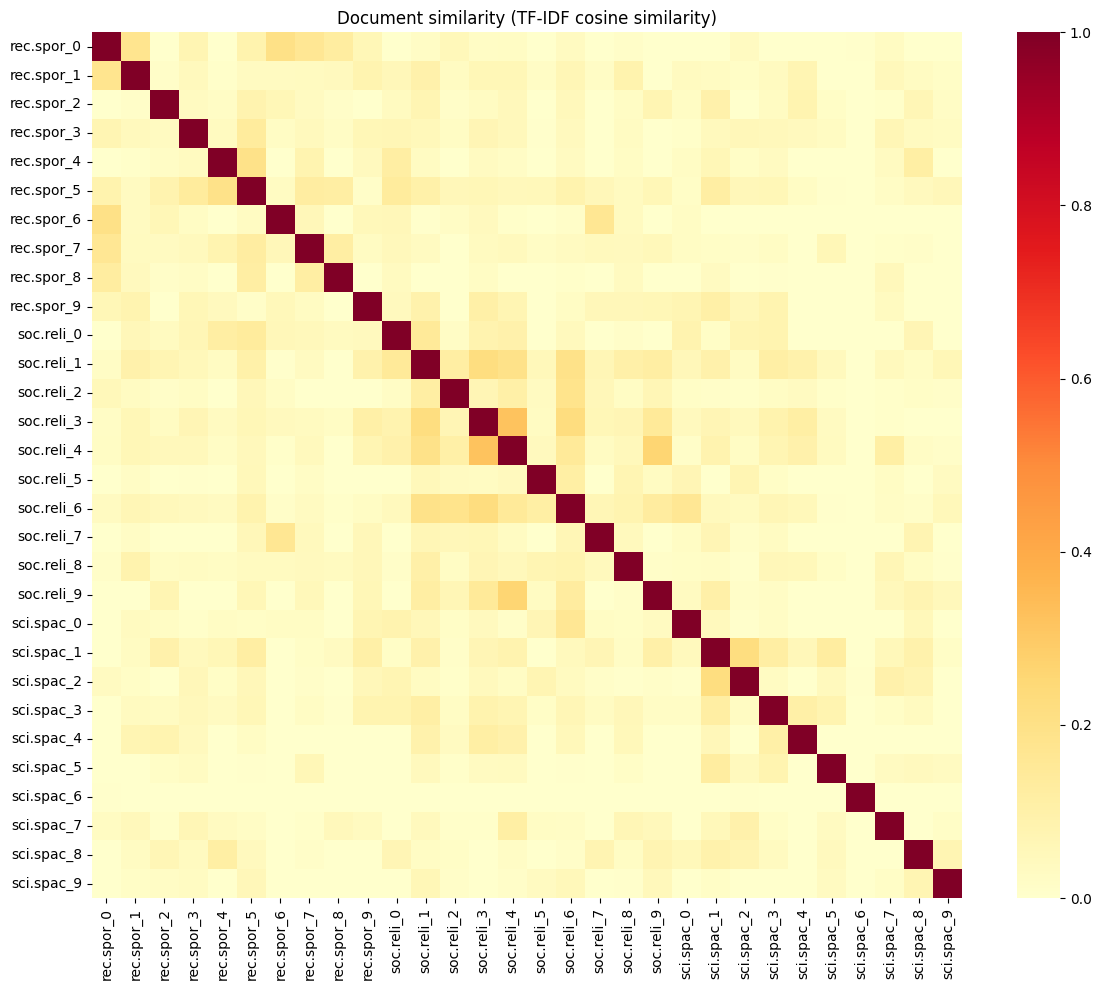

In [25]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**Your answer:**

1- Yes, there is a clear block-diagonal structure. Documents from the same category generally show higher  similarity with each other than with documents from different categories. The soc.religion.christian forms the most cohesive and visible block, with distinct warm orange patches.

2- Most similar: soc.religion.christian and sci.space. Their off-diagonal intersection exhibits warmer yellow/light-orange tints and higher baseline similarity compared to other cross-category pairs.
Least similar: rec.sport.baseball and soc.religion.christian . The off-diagonal intersection between these groups is pale yellow/off-white, reflecting almost zero overlapping TF-IDF terms.

3-Yes, there are a few noticeable off-diagonal sparks, such as between rec.spor_6 and soc.reli_7, as well as soc.reli_4 and sci.spac_9.
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.